In [1]:
# Import Python libraries
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [1]:
# Check the current folder and available files
import os

print("Current folder:", os.getcwd())
print("Files in the current folder:")
for item in os.listdir("."):
    print(item)

Current folder: /Users/khanmontana/messi-analysis
Files in the current folder:
requirements.txt
messi_analysis_from_lab.ipynb
data.csv


In [3]:
# Load the Messi goals dataset
data_path = "data.csv"
df = pd.read_csv(data_path)

# Display the first five rows
df.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,NaN
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo
3,05/06,LaLiga,19,1/15/06,H,FC Barcelona,Athletic Bilbao,2:01,RW,50,2:01,Left-footed shot,Mark van Bommel
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho


In [4]:
# Show the number of rows and columns, and the column names
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

Rows and columns: (704, 13)
Column names: ['Season', 'Competition', 'Matchday', 'Date', 'Venue', 'Club', 'Opponent', 'Result', 'Playing_Position', 'Minute', 'At_score', 'Type', 'Goal_assist']


In [5]:
# Display the first five rows
df.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,NaN
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo
3,05/06,LaLiga,19,1/15/06,H,FC Barcelona,Athletic Bilbao,2:01,RW,50,2:01,Left-footed shot,Mark van Bommel
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho


In [6]:
# Display the last ten rows
df.tail(10)

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist
694,22/23,Ligue 1,12,10/21/22,A,Paris Saint-Germain,AC Ajaccio,0:3,CF,78,0:2,Left-footed shot,Kylian Mbappe
695,22/23,UEFA Champions League,Group Stage,10/25/22,H,Paris Saint-Germain,Maccabi Haifa,7:2,SS,19,1:0,Left-footed shot,Kylian Mbappe
696,22/23,UEFA Champions League,Group Stage,10/25/22,H,Paris Saint-Germain,Maccabi Haifa,7:2,SS,44,4:1,Left-footed shot,Kylian Mbappe
697,22/23,Ligue 1,13,10/29/22,H,Paris Saint-Germain,ESTAC Troyes,4:3,RW,55,2:2,Left-footed shot,Sergio Ramos
698,22/23,Ligue 1,18,1/11/23,H,Paris Saint-Germain,Angers SCO,2:0,AM,72,2:0,Right-footed shot,Nordi Mukiele
699,22/23,Ligue 1,21,2/1/23,A,Paris Saint-Germain,Montpellier HSC,1:3,SS,72,0:2,Left-footed shot,Fabián Ruiz
700,22/23,Ligue 1,22,2/4/23,H,Paris Saint-Germain,FC Toulouse,2:1,SS,58,2:1,Left-footed shot,Achraf Hakimi
701,22/23,Ligue 1,24,2/19/23,H,Paris Saint-Germain,LOSC Lille,4:3,CF,90+5,4:3,Direct free kick,\t
702,22/23,Ligue 1,25,2/26/23,A,Paris Saint-Germain,Olympique Marseille,0:3,CF,29,0:2,Right-footed shot,Kylian Mbappé
703,22/23,Ligue 1,26,3/4/23,H,Paris Saint-Germain,FC Nantes,4:2,CF,12,1:0,Left-footed shot,NaN


In [7]:
# Check the data type of one column
df["Minute"].dtype

<StringDtype(storage='python', na_value=nan)>

In [8]:
# Check data types for all columns
df.dtypes

Season              str
Competition         str
Matchday            str
Date                str
Venue               str
Club                str
Opponent            str
Result              str
Playing_Position    str
Minute              str
At_score            str
Type                str
Goal_assist         str
dtype: object

In [9]:
# 1. Count Messi's goals by competition
goals_by_competition = df.groupby("Competition").size()
print(goals_by_competition.sort_values(ascending=False))

# 2. Replace question marks with missing values, if any exist
df = df.replace("?", np.nan)

# Check missing values in each column
print("\nMissing values by column:")
print(df.isnull().sum())

# 3. Create a numeric goal-minute column while keeping the original Minute column.
# For stoppage time such as '90+1', this records 91.
minute_parts = df["Minute"].astype("string").str.extract(r"^\s*(\d+)\s*(?:\+\s*(\d+))?\s*$")
base_minute = pd.to_numeric(minute_parts[0], errors="coerce")
extra_minute = pd.to_numeric(minute_parts[1], errors="coerce").fillna(0)
df["Minute_numeric"] = base_minute + extra_minute

# 4. Filter goals scored in minute 80 or later
late_goals = df[df["Minute_numeric"] >= 80]
late_goals.head()

Competition
LaLiga                   474
UEFA Champions League    128
Copa del Rey              56
Ligue 1                   21
Supercopa                 14
FIFA Club World Cup        5
UEFA Super Cup             3
Champions League           1
Trophée des Champions      1
Troph�e des Champions      1
dtype: int64

Missing values by column:
Season                0
Competition           0
Matchday              0
Date                  0
Venue                 0
Club                  0
Opponent              0
Result                0
Playing_Position      0
Minute                0
At_score              0
Type                  1
Goal_assist         214
dtype: int64


,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist,Minute_numeric
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho,91
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho,82
6,05/06,LaLiga,21,1/29/06,A,FC Barcelona,RCD Mallorca,0:03,CF,83,0:03,Left-footed shot,Ronaldinho Gaacho,83
8,05/06,LaLiga,24,2/18/06,H,FC Barcelona,Real Betis Balompie,5:01,RW,84,5:01,Left-footed shot,NaN,84
11,06/07,UEFA Champions League,Group Stage,9/27/06,A,FC Barcelona,SV Werder Bremen,1:01,RW,89,1:01,Left-footed shot,Deco,89


In [10]:
# Filter goals scored at home
home_goals = df[df["Venue"] == "H"]
home_goals.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist,Minute_numeric
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho,91
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,NaN,34
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo,51
3,05/06,LaLiga,19,1/15/06,H,FC Barcelona,Athletic Bilbao,2:01,RW,50,2:01,Left-footed shot,Mark van Bommel,50
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho,82


In [11]:
# Descriptive statistics for numeric columns
df.describe()

,Minute_numeric
count,704.0
mean,51.923295
std,25.933163
min,3.0
25%,30.0
50%,54.0
75%,75.0
max,110.0


In [12]:
# Count goals by playing position
df["Playing_Position"].value_counts(dropna=False)

Playing_Position
CF     276
RW     221
RW      95
CF      40
SS      32
SS      23
AM       9
AM       7
LW       1
Name: count, dtype: int64

In [13]:
# Count goals by venue (home vs away)
df["Venue"].value_counts(dropna=False)

Venue
H    420
A    284
Name: count, dtype: int64

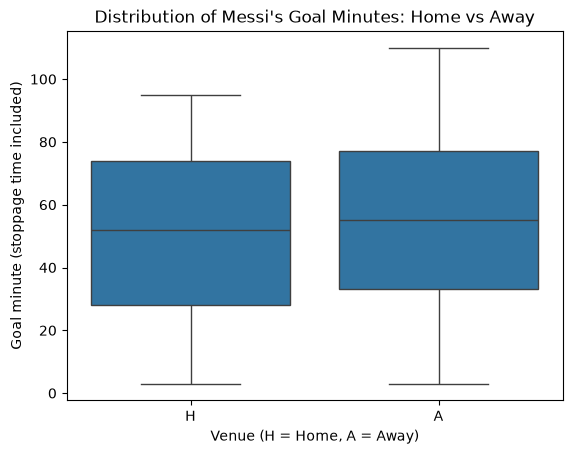

In [14]:
# Boxplot: goal minutes by venue
# Use the numeric minute column created above.
sns.boxplot(x="Venue", y="Minute_numeric", data=df)

plt.title("Distribution of Messi's Goal Minutes: Home vs Away")
plt.xlabel("Venue (H = Home, A = Away)")
plt.ylabel("Goal minute (stoppage time included)")
plt.show()

%pip install scipy